In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os

PROJECT_ROOT = '/content/drive/MyDrive/building_segmentation_project'

folders = [
    f'{PROJECT_ROOT}/data/raw',
    f'{PROJECT_ROOT}/data/patches',
    f'{PROJECT_ROOT}/checkpoints',
    f'{PROJECT_ROOT}/figures',
    f'{PROJECT_ROOT}/kaggle',
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)
    print('Created (or already exists):', folder)

print('\nProject root set to:', PROJECT_ROOT)

Mounted at /content/drive
Created (or already exists): /content/drive/MyDrive/building_segmentation_project/data/raw
Created (or already exists): /content/drive/MyDrive/building_segmentation_project/data/patches
Created (or already exists): /content/drive/MyDrive/building_segmentation_project/checkpoints
Created (or already exists): /content/drive/MyDrive/building_segmentation_project/figures
Created (or already exists): /content/drive/MyDrive/building_segmentation_project/kaggle

Project root set to: /content/drive/MyDrive/building_segmentation_project


In [2]:
!pip install -q segmentation-models-pytorch albumentations

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import segmentation_models_pytorch as smp
import albumentations as A
from PIL import Image

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)
if device.type != 'cuda':
    print('WARNING: No GPU detected. Go to Runtime -> Change runtime type -> select a GPU (T4).')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 5.9 MB/s eta 0:00:00
Using device: cuda


In [3]:
import os, shutil

kaggle_json_drive_path = f'{PROJECT_ROOT}/kaggle/kaggle.json'

assert os.path.exists(kaggle_json_drive_path), (
    f"Could not find kaggle.json at {kaggle_json_drive_path}.\n"
    "Make sure you uploaded it to that exact path in your Drive (see instructions above)."
)

os.makedirs('/root/.kaggle', exist_ok=True)
shutil.copy(kaggle_json_drive_path, '/root/.kaggle/kaggle.json')
os.chmod('/root/.kaggle/kaggle.json', 0o600)

print('Kaggle API key configured successfully.')

Kaggle API key configured successfully.


In [4]:
import os

raw_dir = f'{PROJECT_ROOT}/data/raw'
zip_path = f'{raw_dir}/massachusetts-buildings-dataset.zip'
marker_file = f'{raw_dir}/.download_complete'

if os.path.exists(marker_file):
    print('Dataset already downloaded. Skipping.')
else:
    !kaggle datasets download -d balraj98/massachusetts-buildings-dataset -p "{raw_dir}"
    !unzip -q -o "{zip_path}" -d "{raw_dir}"
    with open(marker_file, 'w') as f:
        f.write('done')
    print('Download and extraction complete.')

Dataset URL: https://www.kaggle.com/datasets/balraj98/massachusetts-buildings-dataset
License(s): other
100% 1.49G/1.49G [00:16<00:00, 98.1MB/s]

Download and extraction complete.


In [5]:
import os

def summarize_dataset_tree(root, max_depth=4):
    root = root.rstrip('/')
    for dirpath, dirnames, filenames in os.walk(root):
        depth = dirpath[len(root):].count(os.sep)
        if depth > max_depth:
            dirnames[:] = []
            continue
        img_like = [f for f in filenames if f.lower().endswith(('.tif', '.tiff', '.png', '.jpg', '.jpeg'))]
        indent = '  ' * depth
        label = os.path.basename(dirpath) or dirpath
        if img_like:
            print(f'{indent}{label}/  <-- {len(img_like)} image files (e.g. {img_like[0]})')
        else:
            print(f'{indent}{label}/')

summarize_dataset_tree(raw_dir)

raw/
  png/
    test/  <-- 10 image files (e.g. 22828930_15.png)
    test_labels/  <-- 10 image files (e.g. 22828930_15.png)
    train/  <-- 137 image files (e.g. 22678915_15.png)
    train_labels/  <-- 137 image files (e.g. 22678915_15.png)
    val/  <-- 4 image files (e.g. 22978945_15.png)
    val_labels/  <-- 4 image files (e.g. 22978945_15.png)
  tiff/
    test/  <-- 10 image files (e.g. 22828930_15.tiff)
    test_labels/  <-- 10 image files (e.g. 22828930_15.tif)
    train/  <-- 137 image files (e.g. 22678915_15.tiff)
    train_labels/  <-- 137 image files (e.g. 22678915_15.tif)
    val/  <-- 4 image files (e.g. 22978945_15.tiff)
    val_labels/  <-- 4 image files (e.g. 22978945_15.tif)


In [6]:
TRAIN_IMG_DIR  = f'{raw_dir}/png/train'
TRAIN_MASK_DIR = f'{raw_dir}/png/train_labels'
VAL_IMG_DIR    = f'{raw_dir}/png/val'
VAL_MASK_DIR   = f'{raw_dir}/png/val_labels'
TEST_IMG_DIR   = f'{raw_dir}/png/test'
TEST_MASK_DIR  = f'{raw_dir}/png/test_labels'

for name, path in [('TRAIN_IMG_DIR', TRAIN_IMG_DIR), ('TRAIN_MASK_DIR', TRAIN_MASK_DIR),
                    ('VAL_IMG_DIR', VAL_IMG_DIR), ('VAL_MASK_DIR', VAL_MASK_DIR),
                    ('TEST_IMG_DIR', TEST_IMG_DIR), ('TEST_MASK_DIR', TEST_MASK_DIR)]:
    n_files = len(os.listdir(path)) if os.path.isdir(path) else 'PATH NOT FOUND'
    print(f'{name}: {path}  ->  {n_files} files')

TRAIN_IMG_DIR: /content/drive/MyDrive/building_segmentation_project/data/raw/png/train  ->  137 files
TRAIN_MASK_DIR: /content/drive/MyDrive/building_segmentation_project/data/raw/png/train_labels  ->  137 files
VAL_IMG_DIR: /content/drive/MyDrive/building_segmentation_project/data/raw/png/val  ->  4 files
VAL_MASK_DIR: /content/drive/MyDrive/building_segmentation_project/data/raw/png/val_labels  ->  4 files
TEST_IMG_DIR: /content/drive/MyDrive/building_segmentation_project/data/raw/png/test  ->  10 files
TEST_MASK_DIR: /content/drive/MyDrive/building_segmentation_project/data/raw/png/test_labels  ->  10 files


Image shape: (1500, 1500, 3) | dtype: uint8
Mask shape: (1500, 1500) | unique values: [  0 255]


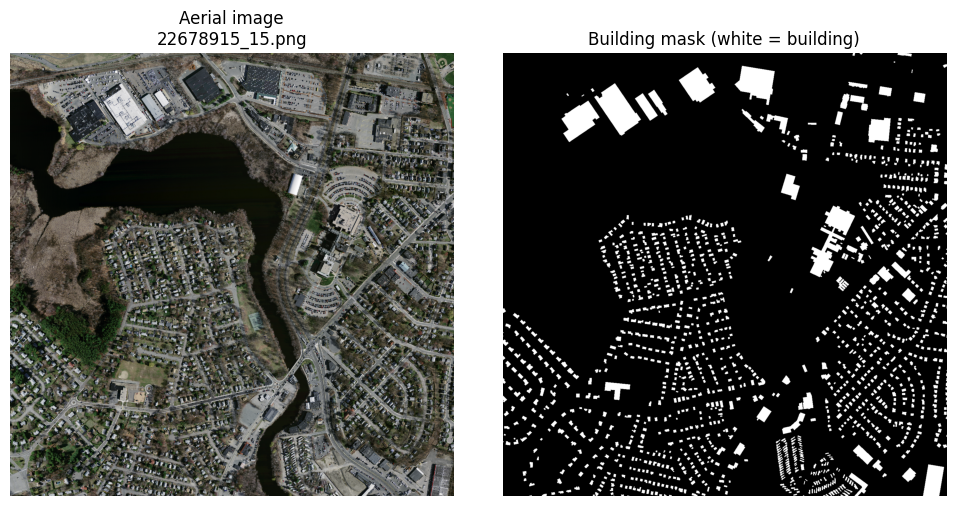

In [7]:
import os

sample_name = sorted(os.listdir(TRAIN_IMG_DIR))[0]
sample_img_path = os.path.join(TRAIN_IMG_DIR, sample_name)
sample_mask_path = os.path.join(TRAIN_MASK_DIR, sample_name)

img = np.array(Image.open(sample_img_path).convert('RGB'))
mask = np.array(Image.open(sample_mask_path).convert('L'))

print('Image shape:', img.shape, '| dtype:', img.dtype)
print('Mask shape:', mask.shape, '| unique values:', np.unique(mask))

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(img)
axes[0].set_title(f'Aerial image\n{sample_name}')
axes[0].axis('off')
axes[1].imshow(mask, cmap='gray')
axes[1].set_title('Building mask (white = building)')
axes[1].axis('off')
plt.tight_layout()
plt.show()

In [8]:
import numpy as np
from PIL import Image
import os

PATCH_SIZE = 256
STRIDE = 256
BUILDING_FRACTION_THRESHOLD = 0.01

patches_root = f'{PROJECT_ROOT}/data/patches'

def make_and_save_patches(img_dir, mask_dir, split_name, patch_size=PATCH_SIZE, stride=STRIDE):
    out_img_dir = f'{patches_root}/{split_name}/images'
    out_mask_dir = f'{patches_root}/{split_name}/masks'
    os.makedirs(out_img_dir, exist_ok=True)
    os.makedirs(out_mask_dir, exist_ok=True)

    manifest_path = f'{patches_root}/{split_name}/manifest.csv'
    if os.path.exists(manifest_path):
        print(f'[{split_name}] manifest already exists, skipping patch generation.')
        import pandas as pd
        return pd.read_csv(manifest_path).to_dict('records')

    records = []
    filenames = sorted(os.listdir(img_dir))
    for fname in filenames:
        img_path = os.path.join(img_dir, fname)
        mask_path = os.path.join(mask_dir, fname)
        if not os.path.exists(mask_path):
            print(f'  WARNING: no matching mask for {fname}, skipping.')
            continue

        image = np.array(Image.open(img_path).convert('RGB'))
        mask = np.array(Image.open(mask_path).convert('L'))
        h, w = image.shape[:2]

        patch_idx = 0
        for y in range(0, h - patch_size + 1, stride):
            for x in range(0, w - patch_size + 1, stride):
                img_patch = image[y:y+patch_size, x:x+patch_size]
                mask_patch = mask[y:y+patch_size, x:x+patch_size]

                building_frac = (mask_patch > 127).mean()
                label = int(building_frac > BUILDING_FRACTION_THRESHOLD)

                base = os.path.splitext(fname)[0]
                patch_name = f'{base}_{patch_idx:03d}.png'
                Image.fromarray(img_patch).save(os.path.join(out_img_dir, patch_name))
                Image.fromarray(mask_patch).save(os.path.join(out_mask_dir, patch_name))

                records.append({
                    'img_path': os.path.join(out_img_dir, patch_name),
                    'mask_path': os.path.join(out_mask_dir, patch_name),
                    'label': label,
                })
                patch_idx += 1

    import pandas as pd
    df = pd.DataFrame(records)
    df.to_csv(manifest_path, index=False)
    print(f'[{split_name}] generated {len(records)} patches '
          f'({df.label.sum()} with buildings, {len(df) - df.label.sum()} without). Saved manifest to {manifest_path}')
    return records

train_records = make_and_save_patches(TRAIN_IMG_DIR, TRAIN_MASK_DIR, 'train')
val_records   = make_and_save_patches(VAL_IMG_DIR, VAL_MASK_DIR, 'val')
test_records  = make_and_save_patches(TEST_IMG_DIR, TEST_MASK_DIR, 'test')

[train] generated 3425 patches (2900 with buildings, 525 without). Saved manifest to /content/drive/MyDrive/building_segmentation_project/data/patches/train/manifest.csv
[val] generated 100 patches (90 with buildings, 10 without). Saved manifest to /content/drive/MyDrive/building_segmentation_project/data/patches/val/manifest.csv
[test] generated 250 patches (225 with buildings, 25 without). Saved manifest to /content/drive/MyDrive/building_segmentation_project/data/patches/test/manifest.csv


In [9]:
import torch
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2
import pandas as pd
import numpy as np
from PIL import Image

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_transform = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1, p=0.3),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ToTensorV2(),
])

eval_transform = A.Compose([
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ToTensorV2(),
])


class PatchClassificationDataset(Dataset):
    def __init__(self, manifest_records, transform):
        self.df = pd.DataFrame(manifest_records)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = np.array(Image.open(row['img_path']).convert('RGB'))
        label = float(row['label'])
        augmented = self.transform(image=image)
        return augmented['image'], torch.tensor([label], dtype=torch.float32)


class PatchSegmentationDataset(Dataset):
    def __init__(self, manifest_records, transform, positive_only=True):
        df = pd.DataFrame(manifest_records)
        self.df = df[df['label'] == 1].reset_index(drop=True) if positive_only else df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = np.array(Image.open(row['img_path']).convert('RGB'))
        mask = np.array(Image.open(row['mask_path']).convert('L'))
        mask = (mask > 127).astype(np.float32)

        augmented = self.transform(image=image, mask=mask)
        img_t = augmented['image']
        mask_t = augmented['mask'].unsqueeze(0).float()
        return img_t, mask_t


train_cls_ds = PatchClassificationDataset(train_records, train_transform)
val_cls_ds   = PatchClassificationDataset(val_records, eval_transform)
test_cls_ds  = PatchClassificationDataset(test_records, eval_transform)

train_seg_ds = PatchSegmentationDataset(train_records, train_transform, positive_only=True)
val_seg_ds   = PatchSegmentationDataset(val_records, eval_transform, positive_only=True)
test_seg_ds  = PatchSegmentationDataset(test_records, eval_transform, positive_only=True)

print(f'Classification -> train: {len(train_cls_ds)}, val: {len(val_cls_ds)}, test: {len(test_cls_ds)}')
print(f'Segmentation   -> train: {len(train_seg_ds)}, val: {len(val_seg_ds)}, test: {len(test_seg_ds)}')

BATCH_SIZE = 32

train_cls_loader = DataLoader(train_cls_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_cls_loader   = DataLoader(val_cls_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_cls_loader  = DataLoader(test_cls_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

train_seg_loader = DataLoader(train_seg_ds, batch_size=16, shuffle=True, num_workers=2)
val_seg_loader   = DataLoader(val_seg_ds, batch_size=16, shuffle=False, num_workers=2)
test_seg_loader  = DataLoader(test_seg_ds, batch_size=16, shuffle=False, num_workers=2)

imgs, labels = next(iter(train_cls_loader))
print('\nClassification batch:', imgs.shape, labels.shape)
imgs, masks = next(iter(train_seg_loader))
print('Segmentation batch:', imgs.shape, masks.shape)

Classification -> train: 3425, val: 100, test: 250
Segmentation   -> train: 2900, val: 90, test: 225

Classification batch: torch.Size([32, 3, 256, 256]) torch.Size([32, 1])
Segmentation batch: torch.Size([16, 3, 256, 256]) torch.Size([16, 1, 256, 256])


In [10]:
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

def build_classifier():
    model = efficientnet_b0(weights=EfficientNet_B0_Weights.IMAGENET1K_V1)
    in_features = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(in_features, 1)
    return model

classifier = build_classifier().to(device)

with torch.no_grad():
    dummy = torch.randn(2, 3, 256, 256).to(device)
    out = classifier(dummy)
    print('Classifier output shape:', out.shape)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 65.3MB/s]


Classifier output shape: torch.Size([2, 1])


In [11]:
import torch.optim as optim
from sklearn.metrics import accuracy_score, f1_score

def run_classifier_epoch(model, loader, criterion, optimizer=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss = 0.0
    all_preds, all_labels = [], []

    context = torch.enable_grad() if is_train else torch.no_grad()
    with context:
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            if is_train:
                optimizer.zero_grad()
            logits = model(imgs)
            loss = criterion(logits, labels)
            if is_train:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * imgs.size(0)
            preds = (torch.sigmoid(logits) > 0.5).float()
            all_preds.extend(preds.cpu().numpy().flatten().tolist())
            all_labels.extend(labels.cpu().numpy().flatten().tolist())

    avg_loss = total_loss / len(loader.dataset)
    acc = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, zero_division=0)
    return avg_loss, acc, f1


NUM_EPOCHS_CLS = 15
LR_CLS = 1e-4

criterion_cls = nn.BCEWithLogitsLoss()
optimizer_cls = optim.Adam(classifier.parameters(), lr=LR_CLS)

cls_checkpoint_path = f'{PROJECT_ROOT}/checkpoints/classifier_best.pt'
best_val_loss = float('inf')
history_cls = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': [], 'train_f1': [], 'val_f1': []}

for epoch in range(1, NUM_EPOCHS_CLS + 1):
    train_loss, train_acc, train_f1 = run_classifier_epoch(classifier, train_cls_loader, criterion_cls, optimizer_cls)
    val_loss, val_acc, val_f1 = run_classifier_epoch(classifier, val_cls_loader, criterion_cls, optimizer=None)

    history_cls['train_loss'].append(train_loss); history_cls['val_loss'].append(val_loss)
    history_cls['train_acc'].append(train_acc); history_cls['val_acc'].append(val_acc)
    history_cls['train_f1'].append(train_f1); history_cls['val_f1'].append(val_f1)

    print(f'Epoch {epoch:2d}/{NUM_EPOCHS_CLS} | train_loss={train_loss:.4f} val_loss={val_loss:.4f} | '
          f'train_acc={train_acc:.3f} val_acc={val_acc:.3f} | train_f1={train_f1:.3f} val_f1={val_f1:.3f}')

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(classifier.state_dict(), cls_checkpoint_path)
        print(f'  -> new best val_loss, checkpoint saved')

print('\nClassifier training complete. Best val loss:', best_val_loss)

Epoch  1/15 | train_loss=0.2953 val_loss=0.1448 | train_acc=0.904 val_acc=0.930 | train_f1=0.943 val_f1=0.960
  -> new best val_loss, checkpoint saved
Epoch  2/15 | train_loss=0.1106 val_loss=0.1421 | train_acc=0.961 val_acc=0.940 | train_f1=0.977 val_f1=0.966
  -> new best val_loss, checkpoint saved
Epoch  3/15 | train_loss=0.0872 val_loss=0.0748 | train_acc=0.971 val_acc=0.970 | train_f1=0.983 val_f1=0.983
  -> new best val_loss, checkpoint saved
Epoch  4/15 | train_loss=0.0741 val_loss=0.0504 | train_acc=0.974 val_acc=0.960 | train_f1=0.985 val_f1=0.977
  -> new best val_loss, checkpoint saved
Epoch  5/15 | train_loss=0.0645 val_loss=0.0529 | train_acc=0.977 val_acc=0.970 | train_f1=0.987 val_f1=0.983
Epoch  6/15 | train_loss=0.0532 val_loss=0.0424 | train_acc=0.984 val_acc=0.980 | train_f1=0.991 val_f1=0.989
  -> new best val_loss, checkpoint saved
Epoch  7/15 | train_loss=0.0528 val_loss=0.0643 | train_acc=0.983 val_acc=0.980 | train_f1=0.990 val_f1=0.989
Epoch  8/15 | train_loss=

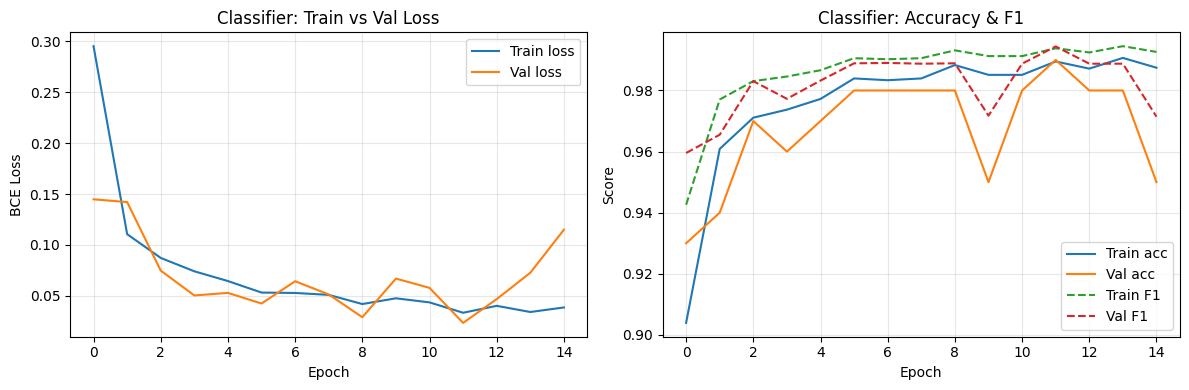

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_cls['train_loss'], label='Train loss')
axes[0].plot(history_cls['val_loss'], label='Val loss')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('BCE Loss'); axes[0].set_title('Classifier: Train vs Val Loss')
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(history_cls['train_acc'], label='Train acc')
axes[1].plot(history_cls['val_acc'], label='Val acc')
axes[1].plot(history_cls['train_f1'], label='Train F1', linestyle='--')
axes[1].plot(history_cls['val_f1'], label='Val F1', linestyle='--')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Score'); axes[1].set_title('Classifier: Accuracy & F1')
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f'{PROJECT_ROOT}/figures/classifier_curves.png', dpi=150)
plt.show()

In [13]:
def build_segmenter():
    model = smp.DeepLabV3Plus(
        encoder_name='mobilenet_v2',
        encoder_weights='imagenet',
        in_channels=3,
        classes=1,
    )
    return model

segmenter = build_segmenter().to(device)

with torch.no_grad():
    dummy = torch.randn(2, 3, 256, 256).to(device)
    out = segmenter(dummy)
    print('Segmenter output shape:', out.shape)

config.json:   0%|          | 0.00/106 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 14.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Segmenter output shape: torch.Size([2, 1, 256, 256])


In [14]:
dice_loss_fn = smp.losses.DiceLoss(mode='binary')
bce_loss_fn = nn.BCEWithLogitsLoss()

def combined_seg_loss(logits, targets):
    return bce_loss_fn(logits, targets) + dice_loss_fn(logits, targets)


def run_segmenter_epoch(model, loader, optimizer=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss = 0.0
    tp_sum = fp_sum = fn_sum = tn_sum = 0

    context = torch.enable_grad() if is_train else torch.no_grad()
    with context:
        for imgs, masks in loader:
            imgs, masks = imgs.to(device), masks.to(device)
            if is_train:
                optimizer.zero_grad()
            logits = model(imgs)
            loss = combined_seg_loss(logits, masks)
            if is_train:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * imgs.size(0)

            probs = torch.sigmoid(logits)
            tp, fp, fn, tn = smp.metrics.get_stats(probs, masks.long(), mode='binary', threshold=0.5)
            tp_sum += tp.sum().item(); fp_sum += fp.sum().item()
            fn_sum += fn.sum().item(); tn_sum += tn.sum().item()

    avg_loss = total_loss / len(loader.dataset)
    tp_t = torch.tensor([tp_sum]); fp_t = torch.tensor([fp_sum])
    fn_t = torch.tensor([fn_sum]); tn_t = torch.tensor([tn_sum])
    iou = smp.metrics.iou_score(tp_t, fp_t, fn_t, tn_t, reduction='micro').item()
    dice = smp.metrics.f1_score(tp_t, fp_t, fn_t, tn_t, reduction='micro').item()
    return avg_loss, iou, dice


NUM_EPOCHS_SEG = 25
LR_SEG = 1e-4
optimizer_seg = optim.Adam(segmenter.parameters(), lr=LR_SEG)

seg_checkpoint_path = f'{PROJECT_ROOT}/checkpoints/segmenter_best.pt'
best_val_iou = 0.0
history_seg = {'train_loss': [], 'val_loss': [], 'train_iou': [], 'val_iou': [], 'train_dice': [], 'val_dice': []}

for epoch in range(1, NUM_EPOCHS_SEG + 1):
    train_loss, train_iou, train_dice = run_segmenter_epoch(segmenter, train_seg_loader, optimizer_seg)
    val_loss, val_iou, val_dice = run_segmenter_epoch(segmenter, val_seg_loader, optimizer=None)

    history_seg['train_loss'].append(train_loss); history_seg['val_loss'].append(val_loss)
    history_seg['train_iou'].append(train_iou); history_seg['val_iou'].append(val_iou)
    history_seg['train_dice'].append(train_dice); history_seg['val_dice'].append(val_dice)

    print(f'Epoch {epoch:2d}/{NUM_EPOCHS_SEG} | train_loss={train_loss:.4f} val_loss={val_loss:.4f} | '
          f'train_iou={train_iou:.3f} val_iou={val_iou:.3f} | train_dice={train_dice:.3f} val_dice={val_dice:.3f}')

    if val_iou > best_val_iou:
        best_val_iou = val_iou
        torch.save(segmenter.state_dict(), seg_checkpoint_path)
        print(f'  -> new best val_iou, checkpoint saved')

print('\nSegmenter training complete. Best val IoU:', best_val_iou)

Epoch  1/25 | train_loss=1.1775 val_loss=0.9309 | train_iou=0.263 val_iou=0.381 | train_dice=0.417 val_dice=0.552
  -> new best val_iou, checkpoint saved
Epoch  2/25 | train_loss=0.9006 val_loss=0.7418 | train_iou=0.371 val_iou=0.446 | train_dice=0.542 val_dice=0.617
  -> new best val_iou, checkpoint saved
Epoch  3/25 | train_loss=0.7963 val_loss=0.6642 | train_iou=0.421 val_iou=0.474 | train_dice=0.593 val_dice=0.643
  -> new best val_iou, checkpoint saved
Epoch  4/25 | train_loss=0.7430 val_loss=0.6114 | train_iou=0.450 val_iou=0.504 | train_dice=0.620 val_dice=0.670
  -> new best val_iou, checkpoint saved
Epoch  5/25 | train_loss=0.7107 val_loss=0.5849 | train_iou=0.467 val_iou=0.525 | train_dice=0.637 val_dice=0.689
  -> new best val_iou, checkpoint saved
Epoch  6/25 | train_loss=0.6892 val_loss=0.5631 | train_iou=0.480 val_iou=0.542 | train_dice=0.649 val_dice=0.703
  -> new best val_iou, checkpoint saved
Epoch  7/25 | train_loss=0.6722 val_loss=0.5528 | train_iou=0.490 val_iou=0.

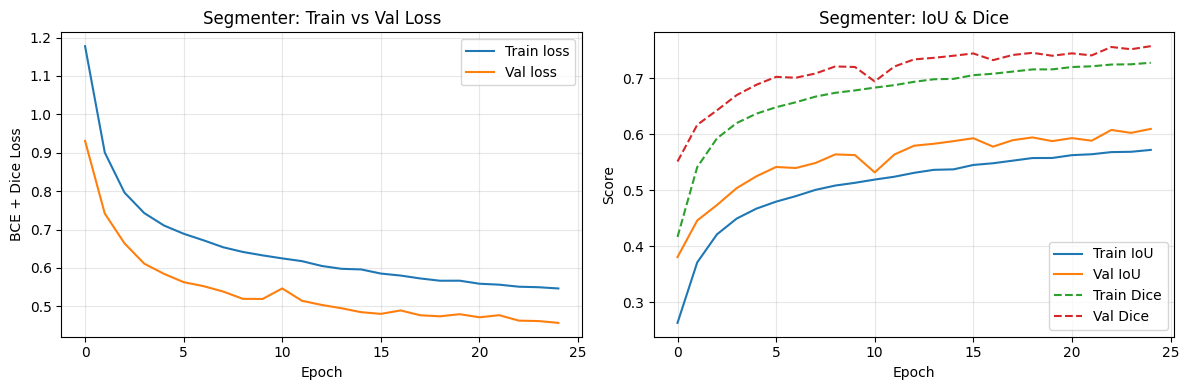

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_seg['train_loss'], label='Train loss')
axes[0].plot(history_seg['val_loss'], label='Val loss')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('BCE + Dice Loss'); axes[0].set_title('Segmenter: Train vs Val Loss')
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(history_seg['train_iou'], label='Train IoU')
axes[1].plot(history_seg['val_iou'], label='Val IoU')
axes[1].plot(history_seg['train_dice'], label='Train Dice', linestyle='--')
axes[1].plot(history_seg['val_dice'], label='Val Dice', linestyle='--')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Score'); axes[1].set_title('Segmenter: IoU & Dice')
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f'{PROJECT_ROOT}/figures/segmenter_curves.png', dpi=150)
plt.show()

In [16]:
from sklearn.metrics import confusion_matrix, classification_report

classifier.load_state_dict(torch.load(cls_checkpoint_path, map_location=device))
segmenter.load_state_dict(torch.load(seg_checkpoint_path, map_location=device))

test_loss, test_acc, test_f1 = run_classifier_epoch(classifier, test_cls_loader, criterion_cls, optimizer=None)
print(f'[Classifier] Test loss={test_loss:.4f}  Test accuracy={test_acc:.3f}  Test F1={test_f1:.3f}')

classifier.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for imgs, labels in test_cls_loader:
        imgs = imgs.to(device)
        logits = classifier(imgs)
        preds = (torch.sigmoid(logits) > 0.5).float().cpu().numpy().flatten()
        all_preds.extend(preds.tolist())
        all_labels.extend(labels.numpy().flatten().tolist())

cm = confusion_matrix(all_labels, all_preds)
print('\nConfusion matrix (rows=true, cols=predicted):')
print(cm)
print('\n', classification_report(all_labels, all_preds, target_names=['no building', 'building']))

[Classifier] Test loss=0.0786  Test accuracy=0.968  Test F1=0.982

Confusion matrix (rows=true, cols=predicted):
[[ 24   1]
 [  7 218]]

               precision    recall  f1-score   support

 no building       0.77      0.96      0.86        25
    building       1.00      0.97      0.98       225

    accuracy                           0.97       250
   macro avg       0.88      0.96      0.92       250
weighted avg       0.97      0.97      0.97       250



In [17]:
test_seg_loss, test_iou, test_dice = run_segmenter_epoch(segmenter, test_seg_loader, optimizer=None)
print(f'[Segmenter] Test loss={test_seg_loss:.4f}  Test IoU={test_iou:.3f}  Test Dice={test_dice:.3f}')

[Segmenter] Test loss=0.4982  Test IoU=0.645  Test Dice=0.785


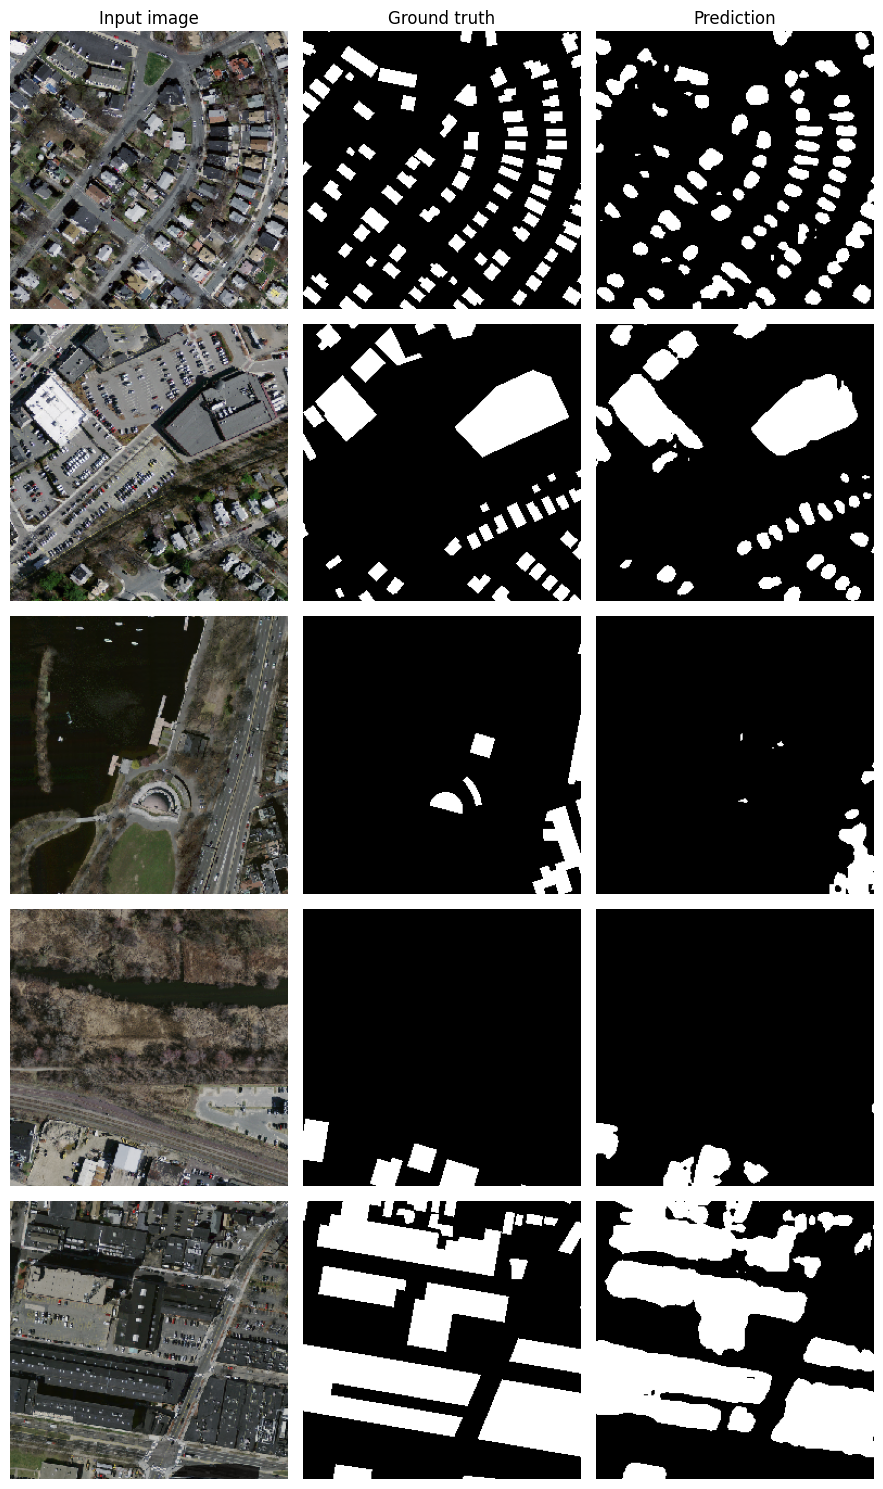

In [18]:
segmenter.eval()
n_samples = 5
fig, axes = plt.subplots(n_samples, 3, figsize=(9, 3 * n_samples))
sample_indices = np.random.choice(len(test_seg_ds), n_samples, replace=False)

with torch.no_grad():
    for row, idx in enumerate(sample_indices):
        img_t, mask_t = test_seg_ds[idx]
        logits = segmenter(img_t.unsqueeze(0).to(device))
        pred_mask = (torch.sigmoid(logits) > 0.5).float().cpu().squeeze().numpy()

        img_display = img_t.permute(1, 2, 0).numpy()
        img_display = img_display * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN)
        img_display = np.clip(img_display, 0, 1)

        axes[row, 0].imshow(img_display); axes[row, 0].set_title('Input image' if row == 0 else ''); axes[row, 0].axis('off')
        axes[row, 1].imshow(mask_t.squeeze().numpy(), cmap='gray'); axes[row, 1].set_title('Ground truth' if row == 0 else ''); axes[row, 1].axis('off')
        axes[row, 2].imshow(pred_mask, cmap='gray'); axes[row, 2].set_title('Prediction' if row == 0 else ''); axes[row, 2].axis('off')

plt.tight_layout()
plt.savefig(f'{PROJECT_ROOT}/figures/sample_predictions.png', dpi=150)
plt.show()

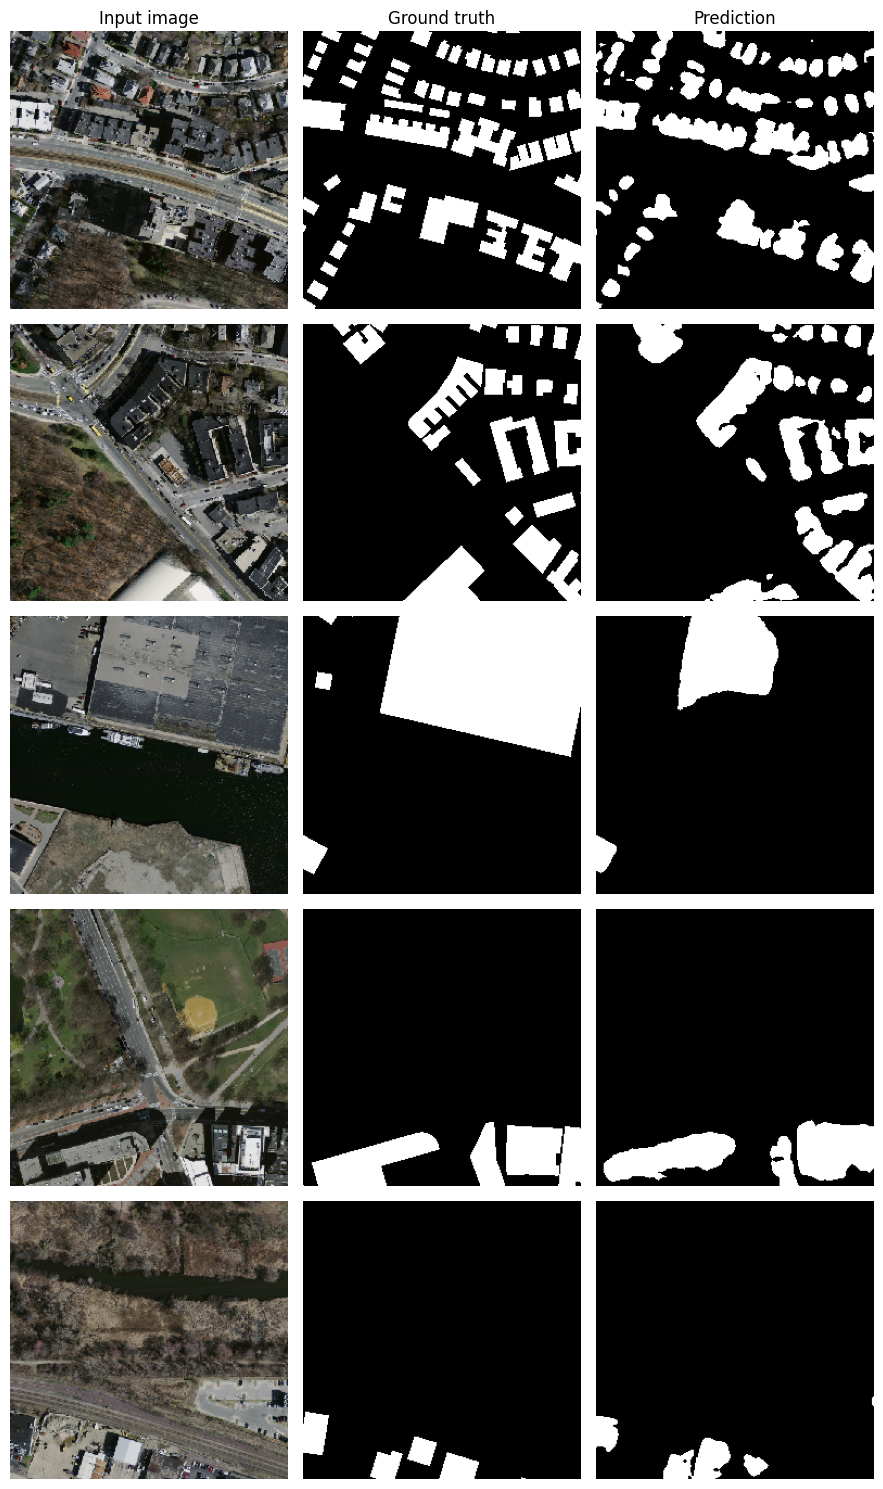

In [19]:
segmenter.eval()
n_samples = 5
fig, axes = plt.subplots(n_samples, 3, figsize=(9, 3 * n_samples))
sample_indices = np.random.choice(len(test_seg_ds), n_samples, replace=False)

with torch.no_grad():
    for row, idx in enumerate(sample_indices):
        img_t, mask_t = test_seg_ds[idx]
        logits = segmenter(img_t.unsqueeze(0).to(device))
        pred_mask = (torch.sigmoid(logits) > 0.5).float().cpu().squeeze().numpy()

        img_display = img_t.permute(1, 2, 0).numpy()
        img_display = img_display * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN)
        img_display = np.clip(img_display, 0, 1)

        axes[row, 0].imshow(img_display); axes[row, 0].set_title('Input image' if row == 0 else ''); axes[row, 0].axis('off')
        axes[row, 1].imshow(mask_t.squeeze().numpy(), cmap='gray'); axes[row, 1].set_title('Ground truth' if row == 0 else ''); axes[row, 1].axis('off')
        axes[row, 2].imshow(pred_mask, cmap='gray'); axes[row, 2].set_title('Prediction' if row == 0 else ''); axes[row, 2].axis('off')

plt.tight_layout()
plt.savefig(f'{PROJECT_ROOT}/figures/sample_predictions.png', dpi=150)
plt.show()

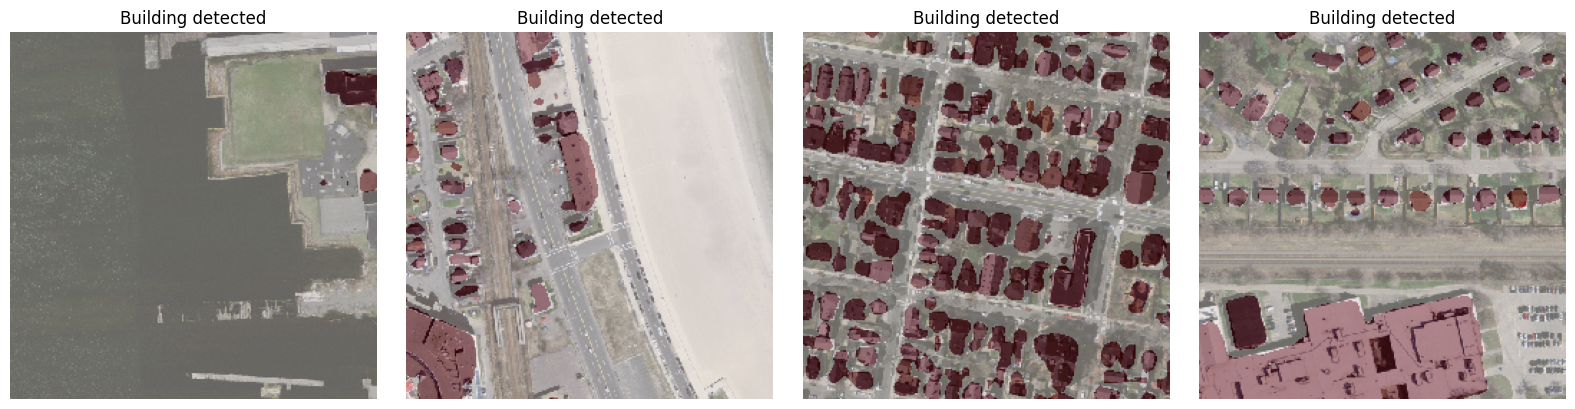

In [20]:
def two_stage_predict(image_array, classifier, segmenter, cls_threshold=0.5, seg_threshold=0.5):
    classifier.eval(); segmenter.eval()
    augmented = eval_transform(image=image_array)
    img_t = augmented['image'].unsqueeze(0).to(device)

    with torch.no_grad():
        cls_prob = torch.sigmoid(classifier(img_t)).item()
    if cls_prob <= cls_threshold:
        return False, None

    with torch.no_grad():
        seg_prob = torch.sigmoid(segmenter(img_t))
        mask = (seg_prob > seg_threshold).float().cpu().squeeze().numpy()
    return True, mask


demo_indices = np.random.choice(len(test_cls_ds.df), 4, replace=False)
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for i, idx in enumerate(demo_indices):
    row = test_cls_ds.df.iloc[idx]
    img = np.array(Image.open(row['img_path']).convert('RGB'))
    has_building, mask = two_stage_predict(img, classifier, segmenter)
    axes[i].imshow(img)
    if has_building:
        axes[i].imshow(mask, cmap='Reds', alpha=0.4)
        axes[i].set_title('Building detected')
    else:
        axes[i].set_title('No building detected')
    axes[i].axis('off')
plt.tight_layout()
plt.savefig(f'{PROJECT_ROOT}/figures/two_stage_demo.png', dpi=150)
plt.show()

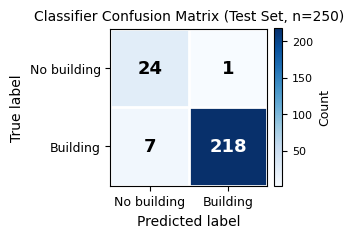

Macro F1: 0.920


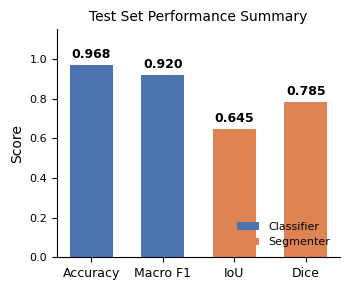

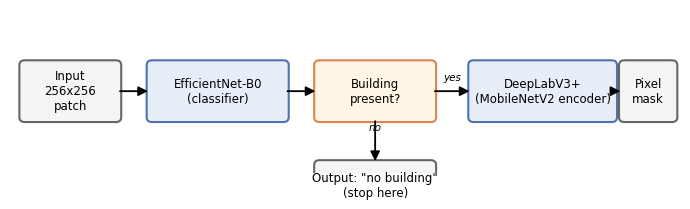

All three figures saved to /content/drive/MyDrive/building_segmentation_project/figures/


In [23]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, f1_score
from matplotlib.patches import Patch, FancyBboxPatch, FancyArrowPatch

# ============================================================
# Figure A: Confusion Matrix (uses your real classifier predictions)
# ============================================================
cm = confusion_matrix(all_labels, all_preds)
macro_f1 = f1_score(all_labels, all_preds, average='macro')
labels = ['No building', 'Building']

fig, ax = plt.subplots(figsize=(3.5, 3.2))
im = ax.imshow(cm, cmap='Blues')
thresh = cm.max() / 2.0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        color = 'white' if cm[i, j] > thresh else 'black'
        ax.text(j, i, str(cm[i, j]), ha='center', va='center',
                color=color, fontsize=13, fontweight='bold')

ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(labels, fontsize=9); ax.set_yticklabels(labels, fontsize=9)
ax.set_xlabel('Predicted label', fontsize=10)
ax.set_ylabel('True label', fontsize=10)
ax.set_title(f'Classifier Confusion Matrix (Test Set, n={len(all_labels)})', fontsize=10)
ax.set_xticks(np.arange(-0.5, 2, 1), minor=True)
ax.set_yticks(np.arange(-0.5, 2, 1), minor=True)
ax.grid(which='minor', color='white', linestyle='-', linewidth=2)
ax.tick_params(which='minor', size=0)
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.ax.tick_params(labelsize=8)
cbar.set_label('Count', fontsize=9)

plt.tight_layout()
plt.savefig(f'{PROJECT_ROOT}/figures/confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()
print(f'Macro F1: {macro_f1:.3f}')


# ============================================================
# Figure B: Metrics Summary Bar Chart (uses your real test scores)
# ============================================================
metrics = ['Accuracy', 'Macro F1', 'IoU', 'Dice']
values = [test_acc, macro_f1, test_iou, test_dice]
colors = ['#4C72B0', '#4C72B0', '#DD8452', '#DD8452']

fig, ax = plt.subplots(figsize=(3.6, 3.0))
bars = ax.bar(metrics, values, color=colors, width=0.6)
for bar, val in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.02, f'{val:.3f}',
            ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.set_ylim(0, 1.15)
ax.set_ylabel('Score', fontsize=10)
ax.set_title('Test Set Performance Summary', fontsize=10)
ax.tick_params(axis='x', labelsize=9); ax.tick_params(axis='y', labelsize=8)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)

legend_elements = [Patch(facecolor='#4C72B0', label='Classifier'),
                   Patch(facecolor='#DD8452', label='Segmenter')]
ax.legend(handles=legend_elements, fontsize=8, loc='lower right', frameon=False)

plt.tight_layout()
plt.savefig(f'{PROJECT_ROOT}/figures/metrics_summary.png', dpi=300, bbox_inches='tight')
plt.show()


# ============================================================
# Figure C: Architecture Diagram (illustrative, no data dependency)
# ============================================================
fig, ax = plt.subplots(figsize=(7.0, 2.2))
ax.set_xlim(0, 10); ax.set_ylim(0, 2.7); ax.axis('off')

def box(x, y, w, h, text, facecolor='#E8EEF7', edgecolor='#4C72B0'):
    b = FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.06,rounding_size=0.08',
                        linewidth=1.5, facecolor=facecolor, edgecolor=edgecolor)
    ax.add_patch(b)
    ax.text(x + w/2, y + h/2, text, ha='center', va='center', fontsize=8.5, wrap=True)

def arrow(x1, y1, x2, y2, label=None):
    a = FancyArrowPatch((x1, y1), (x2, y2), arrowstyle='-|>', mutation_scale=14,
                         linewidth=1.3, color='black')
    ax.add_patch(a)
    if label:
        ax.text((x1+x2)/2, (y1+y2)/2 + 0.18, label, ha='center', fontsize=7.5, style='italic')

box(0.2, 0.9, 1.4, 0.9, "Input\n256x256\npatch", facecolor='#F5F5F5', edgecolor='#666666')
box(2.1, 0.9, 2.0, 0.9, "EfficientNet-B0\n(classifier)", facecolor='#E8EEF7', edgecolor='#4C72B0')
arrow(1.6, 1.35, 2.1, 1.35)
box(4.6, 0.9, 1.7, 0.9, "Building\npresent?", facecolor='#FFF6E5', edgecolor='#DD8452')
arrow(4.1, 1.35, 4.6, 1.35)
box(4.6, -0.55, 1.7, 0.7, 'Output: "no building"\n(stop here)', facecolor='#F5F5F5', edgecolor='#666666')
arrow(5.45, 0.9, 5.45, 0.15, label='no')
box(6.9, 0.9, 2.1, 0.9, "DeepLabV3+\n(MobileNetV2 encoder)", facecolor='#E8EEF7', edgecolor='#4C72B0')
arrow(6.3, 1.35, 6.9, 1.35, label='yes')
box(9.15, 0.9, 0.75, 0.9, "Pixel\nmask", facecolor='#F5F5F5', edgecolor='#666666')
arrow(9.0, 1.35, 9.15, 1.35)

plt.tight_layout()
plt.savefig(f'{PROJECT_ROOT}/figures/architecture_diagram.png', dpi=300, bbox_inches='tight')
plt.show()

print("All three figures saved to", f'{PROJECT_ROOT}/figures/')